# Streaming

In [ ]:
import os
import pyrealsense2 as rs
import numpy as np
import cv2

In [ ]:
# config classes
pipeline = rs.pipeline()
config = rs.config()

# Get device product line for setting a supporting resolution
pipeline_wrapper = rs.pipeline_wrapper(pipeline)
pipeline_profile = config.resolve(pipeline_wrapper)

device = pipeline_profile.get_device()
device_product_line = str(device.get_info(rs.camera_info.product_line))

found_rgb = False
for s in device.sensors:
    if s.get_info(rs.camera_info.name) == "RGB Camera":
        found_rgb = True
        break
if not found_rgb:
    print("The demo requires Depth camera with Color sensor")
    exit(0)


In [ ]:
# depth
config.enable_stream(
    stream_type=rs.stream.depth, width=640, height=480, format=rs.format.z16, framerate=60
)
# color
config.enable_stream(
    stream_type=rs.stream.color, width=640, height=480, format=rs.format.bgr8, framerate=60
)
# infra
# config.enable_stream(
#     stream_type=rs.stream.infrared, width=640, height=480, format=rs.format.bgr8 , framerate=60
# )

# is selected config (for specific pipeline) valid
if config.can_resolve(pipeline):
    print('config OK')
else:
    print('baj van')

In [ ]:
# Start streaming
pipeline.start(config)

try:
    while True:

        # Wait for a coherent pair of frames: depth and color
        frames = pipeline.wait_for_frames()
        depth_frame = frames.get_depth_frame()
        color_frame = frames.get_color_frame()
        # infra_frame = frames.get_infrared_frame()

        if not depth_frame or not color_frame:
            continue

        # Convert images to numpy arrays
        depth_image = np.asanyarray(depth_frame.get_data())
        color_image = np.asanyarray(color_frame.get_data())
        # infra_image = np.asanyarray(infra_frame.get_data())

        # Apply colormap on depth image (image must be converted to 8-bit per pixel first)
        depth_colormap = cv2.applyColorMap(
            cv2.convertScaleAbs(depth_image, alpha=0.03), cv2.COLORMAP_JET
        )

        depth_colormap_dim = depth_colormap.shape
        color_colormap_dim = color_image.shape

        # If depth and color resolutions are different, resize color image to match depth image for display
        if depth_colormap_dim != color_colormap_dim:
            resized_color_image = cv2.resize(
                color_image,
                dsize=(depth_colormap_dim[1], depth_colormap_dim[0]),
                interpolation=cv2.INTER_AREA,
            )
            images = np.hstack((resized_color_image, depth_colormap))
        else:
            images = np.hstack((color_image, depth_colormap))
            # images = np.hstack((color_image, depth_colormap, infra_image))

        # Show images
        cv2.namedWindow("RealSense", cv2.WINDOW_AUTOSIZE)
        cv2.imshow("RealSense", images)

        # press q to exit without crash
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break
    cv2.destroyAllWindows()

finally:

    # Stop streaming
    pipeline.stop()


In [ ]:
infra_image.shape, color_image.shape, depth_image.shape

In [ ]:
ord('e')

# Recording

In [2]:
import os
import time
import cv2
import numpy as np
import pyrealsense2 as rs
from Util.util import resolution_presets

In [3]:
# set recording name & parameters
recording_name = "pull1"
recording_file_name = os.path.join("data", recording_name, recording_name + ".db3")

preset = resolution_presets["640x360@90"]  # '848x480@60', '640x360@90', '480x270@90'

RECORDING_DURATION = 65  # seconds


if not os.path.isdir(os.path.join("data", recording_name)):
    os.mkdir(os.path.join("data", recording_name))

# config classes
pipeline = rs.pipeline()
config = rs.config()

# depth
config.enable_stream(
    stream_type=rs.stream.depth,
    width=preset["width"],
    height=preset["height"],
    format=rs.format.z16,
    framerate=preset["fps"],
)
# color
config.enable_stream(
    stream_type=rs.stream.color,
    width=preset["width"],
    height=preset["height"],
    format=rs.format.bgr8,
    framerate=preset["fps"],
)
# enable recording
config.enable_record_to_file(file_name=recording_file_name)
queue = rs.frame_queue(capacity=200, keep_frames=True)

# is selected config (for specific pipeline) valid
if not config.can_resolve(pipeline):
    raise RuntimeError(f"Config can't be resolved with preset: {preset}")
else:
    for key, item in preset.items():
        print(f'{key:<8} {item}')

width    640
height   360
fps      90


In [5]:
# ask before overwriting an existing recording
if os.path.exists(recording_file_name):
    answer = input(f"{recording_file_name} already exists. Overwrite? (y/n) ")
    if answer.strip().lower() != "y":
        raise FileExistsError(
            f"{recording_file_name} already exists, set a different recording_name"
        )
    os.remove(recording_file_name)

pipeline.start(config, queue)

cv2.namedWindow("RealSense", cv2.WINDOW_AUTOSIZE)
start_time = time.time()
try:
    while time.time() - start_time < RECORDING_DURATION:
        frames = queue.wait_for_frame()
        frames = frames.as_frameset()

        depth_frame = frames.get_depth_frame()
        color_frame = frames.get_color_frame()

        if not depth_frame or not color_frame:
            continue

        depth_image = np.asanyarray(depth_frame.get_data())
        color_image = np.asanyarray(color_frame.get_data())

        # Apply colormap on depth image (image must be converted to 8-bit per pixel first)
        depth_colormap = cv2.applyColorMap(
            cv2.convertScaleAbs(depth_image, alpha=0.03), cv2.COLORMAP_JET
        )

        display_images = np.hstack((color_image, depth_colormap))

        cv2.imshow("RealSense", display_images)

        # press q to exit without crash
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break


finally:
    pipeline.stop()
    cv2.destroyAllWindows()

FileExistsError: data\pull1\pull1.db3 already exists, set a different recording_name

## Calibration image

In [7]:
calibration_image_out_file_name = os.path.join("data", recording_name, "calibration_image.png")

# ask before overwriting an existing calibration image
if os.path.exists(calibration_image_out_file_name):
    answer = input(f"{calibration_image_out_file_name} already exists. Overwrite? (y/n) ")
    if answer.strip().lower() != "y":
        raise FileExistsError(f"{calibration_image_out_file_name} already exists")

pipeline = rs.pipeline()
config = rs.config()

config.enable_stream(
    stream_type=rs.stream.color,
    width=preset["width"],
    height=preset["height"],
    format=rs.format.bgr8,
    framerate=preset["fps"],
)
profile = pipeline.start(config)
start_time = time.time()

try:
    while time.time() - start_time < 5:

        frames = pipeline.wait_for_frames()
        color_frame = frames.get_color_frame()

        if not color_frame:
            continue

        color_image = np.asanyarray(color_frame.get_data())
        if time.time() - start_time > 2:
            cv2.imwrite(calibration_image_out_file_name, color_image)
            print(f"saved {calibration_image_out_file_name}")
            break
finally:
    pipeline.stop()

saved data\pull1\calibration_image.png


# Align, save color & depth

.db3 --> filter -> align -> .mp4 (color), .mkv (depth), .bin (timestamps), .json (metadata)

In [13]:
import os
import json
import subprocess
import numpy as np
import pyrealsense2 as rs
import glob
from tqdm.auto import tqdm
from Util.util import create_ffmpeg_command
%matplotlib ipympl

recording_name = "pull1"
out_folder = os.path.join("data", recording_name)

if os.path.isdir(out_folder):
    recording_file_name = os.path.join(out_folder, recording_name + ".db3")
    if not os.path.exists(recording_file_name):
        raise FileNotFoundError(f'File {recording_file_name} does not exist')
    out_filename_color = os.path.join(out_folder,recording_name+"_color.mp4")
    out_filename_depth = os.path.join(out_folder, recording_name+"_depth.mkv")
    out_filename_timestamps_color = os.path.join(out_folder, recording_name+"_timestamps_color.bin")
    out_filename_timestamps_depth = os.path.join(out_folder, recording_name+"_timestamps_depth.bin")
    out_filename_metadata = os.path.join(out_folder, recording_name+"_metadata.json")
else:
    raise FileNotFoundError(f"Folder {recording_name} does not exist")

## filter -> align

In [14]:
# config
pipeline = rs.pipeline()
config = rs.config()
config.enable_device_from_file(recording_file_name, repeat_playback=False)

profile = pipeline.start(config)

# Get depth intrinsics
depth_profile = profile.get_stream(rs.stream.depth)
depth_intrinsics = depth_profile.as_video_stream_profile().get_intrinsics()

# Get color intrinsics
color_profile = profile.get_stream(rs.stream.color)
color_intrinsics = color_profile.as_video_stream_profile().get_intrinsics()

playback = profile.get_device().as_playback()
playback.set_real_time(False)

# align_to=rs.stream.color/infra... -> aligns depth to other
# align_to=RS2_STREAM_DEPTH -> align other stream to depth
align = rs.align(align_to=rs.stream.color)

depth_sensor = profile.get_device().first_depth_sensor()
depth_scale = depth_sensor.get_depth_scale()

# filters
threshold = rs.threshold_filter(min_dist=0.05, max_dist=7.0)
depth_to_disparity = rs.disparity_transform(True)
spatial = rs.spatial_filter()
spatial.set_option(rs.option.filter_magnitude, 2)
spatial.set_option(rs.option.filter_smooth_alpha, 0.5)
spatial.set_option(rs.option.filter_smooth_delta, 20)
temporal = rs.temporal_filter()
temporal.set_option(rs.option.filter_smooth_alpha, 0.7)
temporal.set_option(rs.option.filter_smooth_delta, 15)
temporal.set_option(rs.option.holes_fill, 0)
disparity_to_depth = rs.disparity_transform(False)

ffmpeg_color = create_ffmpeg_command(
    width=color_intrinsics.width,
    height=color_intrinsics.height,
    fps=color_profile.fps(),
    encoder="h264_qsv",
    out_filename=out_filename_color,
)
video_color = subprocess.Popen(ffmpeg_color, stdin=subprocess.PIPE)

ffmpeg_depth = [
    "ffmpeg",
    "-y",
    "-loglevel",
    "error",
    "-f",
    "rawvideo",
    "-pix_fmt",
    "gray16le",
    "-s",
    f"{color_intrinsics.width}x{color_intrinsics.height}",
    "-r",
    str(color_profile.fps()),
    "-i",
    "-",
    "-c:v",
    "ffv1",
    out_filename_depth,
]
video_depth = subprocess.Popen(ffmpeg_depth, stdin=subprocess.PIPE)


# output files
timestamps_color_out = open(out_filename_timestamps_color, "wb", buffering=1024 * 1024)
timestamps_depth_out = open(out_filename_timestamps_depth, "wb", buffering=1024 * 1024)

frame_count = 0

print(f"Input:  {recording_file_name}\n")
# the frame count is only known at the end of playback, so the bar shows count and rate only
progress_bar = tqdm(desc="Converting", unit="frame")

try:
    while True:
        try:
            frames = pipeline.wait_for_frames()
        except RuntimeError:
            # at the end of the file wait_for_frames times out and playback is stopped;
            # any other error must not end the conversion as if it had finished
            if playback.current_status() == rs.playback_status.stopped:
                break
            raise

        # filter the raw depth first; the filters process the depth frame of the frameset
        # and pass the color frame through, so the result can still be aligned
        filtered = threshold.process(frames)
        filtered = depth_to_disparity.process(filtered)
        filtered = spatial.process(filtered)
        filtered = temporal.process(filtered)
        filtered = disparity_to_depth.process(filtered)

        # then align the filtered depth to the color camera
        # NOTE: later only the color intrinsics are needed
        aligned_frames = align.process(filtered.as_frameset())
        color_frame = aligned_frames.get_color_frame()
        depth_frame = aligned_frames.get_depth_frame()

        if not color_frame or not depth_frame:
            continue

        color_image = np.asanyarray(color_frame.get_data())
        depth_image = np.asanyarray(depth_frame.get_data())

        video_color.stdin.write(color_image.tobytes())
        video_depth.stdin.write(depth_image.tobytes())

        # the frameset timestamp follows the depth frame, but the keypoints come from the color
        # frame, so get_frame_times has to remove duplicates and place frames by the color timestamp;
        # the depth timestamps show where the depth frame repeats instead
        timestamps_color_out.write(np.float64(frames.get_color_frame().get_timestamp()).tobytes())
        timestamps_depth_out.write(np.float64(frames.get_depth_frame().get_timestamp()).tobytes())

        frame_count += 1
        progress_bar.update(1)

finally:
    progress_bar.close()

    video_color.stdin.close()
    color_exit_code = video_color.wait()

    video_depth.stdin.close()
    depth_exit_code = video_depth.wait()

    timestamps_color_out.close()
    timestamps_depth_out.close()

    pipeline.stop()

# checked after cleanup, so an error in the loop isn't hidden by this one
if color_exit_code != 0:
    raise RuntimeError(f"ffmpeg color encoding failed with exit code {color_exit_code}")
if depth_exit_code != 0:
    raise RuntimeError(f"ffmpeg depth encoding failed with exit code {depth_exit_code}")

metadata = {
    "frames": frame_count,
    "width": color_intrinsics.width,
    "height": color_intrinsics.height,
    "fps": color_profile.fps(),
    "color": out_filename_color,
    "depth": out_filename_depth,
    "depth_format": "uint16",
    "depth_alignment": "depth_to_color",
    "depth_scale_meters": depth_scale,
    "timestamps_color": out_filename_timestamps_color,
    "timestamps_depth": out_filename_timestamps_depth,
    "timestamp_unit": "milliseconds",
    "depth_intrinsics": {
        "width": depth_intrinsics.width,
        "height": depth_intrinsics.height,
        "ppx": depth_intrinsics.ppx,
        "ppy": depth_intrinsics.ppy,
        "fx": depth_intrinsics.fx,
        "fy": depth_intrinsics.fy,
        "model": str(depth_intrinsics.model),
        "coeffs": depth_intrinsics.coeffs,
    },
    "color_intrinsics": {
        "width": color_intrinsics.width,
        "height": color_intrinsics.height,
        "ppx": color_intrinsics.ppx,
        "ppy": color_intrinsics.ppy,
        "fx": color_intrinsics.fx,
        "fy": color_intrinsics.fy,
        "model": str(color_intrinsics.model),
        "coeffs": color_intrinsics.coeffs,
    },
}

with open(out_filename_metadata, "w") as f:
    json.dump(metadata, f, indent=2)

print("\n\nDone.")
print(f"Frames: {frame_count}")
print(f"Color:  {out_filename_color}")
print(f"Depth:  {out_filename_depth}")
print(f"Color timestamps:  {out_filename_timestamps_color}")
print(f"Depth timestamps:  {out_filename_timestamps_depth}")
print(f"Metadata:  {out_filename_metadata}")

Input:  data\pull1\pull1.db3



Converting: 0frame [00:00, ?frame/s]



Done.
Frames: 5863
Color:  data\pull1\pull1_color.mp4
Depth:  data\pull1\pull1_depth.mkv
Color timestamps:  data\pull1\pull1_timestamps_color.bin
Depth timestamps:  data\pull1\pull1_timestamps_depth.bin
Metadata:  data\pull1\pull1_metadata.json


# Get 2D keypoints

mp4 --> 2D keypoints (camera frame)

In [15]:
import os
import sys
import cv2
import json
import importlib
import numpy as np
from Util.util import models, Custom, labels_17, labels_26
from pathlib import Path
import onnxruntime as ort
from tqdm.auto import tqdm

rtmlib_module = importlib.import_module("rtmlib")

device = "cuda"
backend = "onnxruntime"
openpose_skeleton = False

site_packages = Path(sys.prefix) / "Lib" / "site-packages"
cuda_bin = site_packages / "nvidia" / "cu13" / "bin" / "x86_64"
cudnn_bin = site_packages / "nvidia" / "cudnn" / "bin"

os.add_dll_directory(str(cuda_bin))
os.add_dll_directory(str(cudnn_bin))
ort.preload_dlls(
    cuda=True,
    cudnn=True,
    directory=str(cuda_bin),
)

print("ORT providers:", ort.get_available_providers())

detector = "yolo_nano"  #'yolo_nano', 'yolo_m', 'yolo_l', 'yolo_x'
pose_estimator = "rtm_pose_x_17"  #'rtm_pose_t_17', 'rtm_pose_m_17', 'rtm_pose_l_17', 'rtm_pose_x_17', 'vit_pose_l_17', 'rtm_pose_t_26', 'rtm_pose_m_26', 'rtm_pose_l_26', 'rtm_pose_x_26'
labels = labels_17  # labels_26, labels_17
custom = Custom(
    det_class="YOLOX",  #'RTMDet',
    det=models["detectors"][detector]["path"],
    det_input_size=models["detectors"][detector]["input_size"],
    pose_class="RTMPose",  # 'RTMPose', 'ViTPose'
    pose=models["pose"][pose_estimator]["path"],
    pose_input_size=models["pose"][pose_estimator]["input_size"],
    backend=backend,
    device=device,
)

ORT providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
load C:\Users\unger\.cache\rtmlib\hub\checkpoints\yolox_nano_8xb8-300e_humanart-40f6f0d0.onnx with onnxruntime backend
load C:\Users\unger\.cache\rtmlib\hub\checkpoints\rtmpose-x_simcc-body7_pt-body7_700e-384x288-71d7b7e9_20230629.onnx with onnxruntime backend


In [16]:
recording_name = "pull1"
input_video_filename = os.path.join("data", recording_name, recording_name + "_color.mp4")
filename_metadata = os.path.join("data", recording_name, recording_name + "_metadata.json")
out_filename_keypoints_2d = os.path.join("data", recording_name, recording_name + "_keypoints_2d")
if not os.path.exists(input_video_filename):
    raise FileNotFoundError(f"File {input_video_filename} does not exist")
if not os.path.exists(filename_metadata):
    raise FileNotFoundError(f"File {filename_metadata} does not exist")

with open(filename_metadata) as f:
    metadata = json.load(f)

print(f"processing: {input_video_filename}")

# containers to store the results in
keypoints_2d = []
mid_shoulder = []

cap = cv2.VideoCapture(input_video_filename)
if cap.isOpened() == False:
    raise FileNotFoundError(f"Error opening video file: {input_video_filename}")

total_num_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
processed_num_frames = 0
progress_bar = tqdm(total=total_num_frames, unit="frame")
ppl = []

from Util.util import hex_to_bgr

colors = [hex_to_bgr("#6AE611"), hex_to_bgr("#B82EC7"), hex_to_bgr("#F1791D")]

while cap.isOpened():
    ret, frame = cap.read()

    if ret == True:
        processed_num_frames += 1

        # rotate frame to portrait mode so pose estimation works
        frame = cv2.rotate(frame, cv2.ROTATE_90_COUNTERCLOCKWISE)
        # frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)

        width = frame.shape[1]
        height = frame.shape[0]

        POI = np.array([width / 2, height / 2])

        # inference
        keypoints, scores = custom(frame)
        # print(keypoints.shape)
        num_ppl = keypoints.shape[0]
        ppl.append(num_ppl)

        # TODO: add tracking or ROI
        # store results (frames * kpt * (x,y)), remove multiperson cases
        if keypoints.ndim > 2:

            # distance_to_poi = lambda person: np.linalg.norm(POI - (person[19, :] + person[18, :]) / 2.0)
            # detected_persons = sorted(keypoints,key=distance_to_poi)
            # for person_idx, keypoints in enumerate(detected_persons):
            #     for kpt in keypoints[:, :]:
            #         cv2.circle(frame, (int(kpt[0]), int(kpt[1])), 3, colors[person_idx], 2)
            # keypoints = detected_persons[0]
            keypoints = keypoints[0, :, :]

        keypoints = np.squeeze(keypoints)

        keypoints_2d.append(keypoints)
        progress_bar.update(1)

        # preview only every 10th frame, drawing every frame slows the loop down
        if processed_num_frames % 100 == 0:
            cv2.circle(frame, (int(POI[0]), int(POI[1])), 3, (255, 0, 0), 2)
            # cv2.circle(frame,(int(POI[1]), int(POI[0])),3,(255,0,0),2)
            for kpt in keypoints[:, :]:
                cv2.circle(frame, (int(kpt[0]), int(kpt[1])), 3, (0, 255, 0), 2)

            cv2.imshow("Image", cv2.resize(frame, (int(width), int(height))))

            # Press Q on keyboard to exit (only checked on preview frames)
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break
    else:
        break
progress_bar.close()
cap.release()
cv2.destroyAllWindows()

keypoints_2d = np.asarray(keypoints_2d)

# every later stage pairs keypoint frame i with timestamp i, so a stopped or short run must not be saved
if len(keypoints_2d) != metadata["frames"]:
    raise RuntimeError(
        f"got keypoints for {len(keypoints_2d)} frames, but the conversion wrote {metadata['frames']} frames"
    )

# add mid_shoulder (between left and right)
left_shoulder = keypoints_2d[:, labels.index("left_shoulder"), :]
right_shoulder = keypoints_2d[:, labels.index("right_shoulder"), :]
mid_shoulder = np.nanmean([left_shoulder, right_shoulder], axis=0)
mid_shoulder = np.expand_dims(np.array(mid_shoulder), axis=1)
keypoints_2d = np.hstack((keypoints_2d, mid_shoulder))

# add mid_hip (between left and right)
left_hip = keypoints_2d[:, labels.index("left_hip"), :]
right_hip = keypoints_2d[:, labels.index("right_hip"), :]
mid_hip = np.nanmean([left_hip, right_hip], axis=0)
mid_hip = np.expand_dims(np.array(mid_hip), axis=1)
keypoints_2d = np.hstack((keypoints_2d, mid_hip))

np.save(out_filename_keypoints_2d, keypoints_2d)

print(f"shape of keypoints_2d:  {keypoints_2d.shape}")

processing: data\pull1\pull1_color.mp4


  0%|          | 0/5863 [00:00<?, ?frame/s]

shape of keypoints_2d:  (5863, 19, 2)


# Get 3D keypoints

In [17]:
import os
import json
import subprocess
import numpy as np
import pyrealsense2 as rs
from tqdm.auto import tqdm
from Util.util import create_intrinsics_object, sample_depth_patch

recording_name = "pull1"
folder_name = os.path.join("data", recording_name)
filename_keypoints_2d = os.path.join(folder_name, recording_name + "_keypoints_2d.npy")
filename_metadata = os.path.join(folder_name, recording_name + "_metadata.json")
filename_depth = os.path.join(folder_name, recording_name + "_depth.mkv")
out_filename_keypoints_3d = os.path.join(folder_name, recording_name + "_keypoints_3d.npy")

for filename in [filename_keypoints_2d, filename_metadata, filename_depth]:
    if not os.path.exists(filename):
        raise FileNotFoundError(f"File {filename} does not exist")

keypoints_2d = np.load(filename_keypoints_2d)
with open(filename_metadata) as f:
    metadata = json.load(f)

print(f"keypoints_2d: {keypoints_2d.shape}")
print(f"metadata loaded: {filename_metadata}")

keypoints_2d: (5863, 19, 2)
metadata loaded: data\pull1\pull1_metadata.json


In [18]:
depth_scale = metadata["depth_scale_meters"]  # conversion to meters
intrinsics = create_intrinsics_object(intrinsics_dict=metadata["color_intrinsics"])

W = intrinsics.width
H = intrinsics.height
n_frames = metadata["frames"]

bytes_per_frame = W * H * 2  # uint16 = 2 bytes/pixel

ffmpeg_cmd = ["ffmpeg", "-i", filename_depth, "-f", "rawvideo", "-pix_fmt", "gray16le", "-"]
video_depth = subprocess.Popen(
    ffmpeg_cmd, stdout=subprocess.PIPE, stderr=subprocess.DEVNULL, bufsize=10**8
)

keypoints_3d = []
frame_idx = 0
progress_bar = tqdm(total=n_frames, unit="frame")
while frame_idx < n_frames:
    raw_frame_data = video_depth.stdout.read(bytes_per_frame)
    if len(raw_frame_data) < bytes_per_frame:
        break
    current_frame_depth_map = np.frombuffer(raw_frame_data, dtype=np.uint16).reshape(H, W)
    current_frame_depth_map = current_frame_depth_map.copy()

    current_keypoints_2d = keypoints_2d[frame_idx, :, :]

    current_keypoints_3d = []
    # NOTE: pose estimation runs in portrait, x,y must be landscape for depth
    for kpt_idx, (x_portrait, y_portrait) in enumerate(current_keypoints_2d):
        # 90 deg clockwise rotation of the physical camera
        x_landscape = int(round(W - 1 - y_portrait))
        y_landscape = int(round(x_portrait))

        # 90 deg counterclockwise
        # x_landscape = int(round(y_portrait))
        # y_landscape = int(round(H - 1 - x_portrait))

        if not (0 <= x_landscape < W and 0 <= y_landscape < H):
            current_keypoints_3d.append([np.nan, np.nan, np.nan])
            continue

        d = (
            sample_depth_patch(
                depth_map=current_frame_depth_map, x=x_landscape, y=y_landscape, radius=3
            )
            * depth_scale
        )

        if d <= 0:  # invalid/missing depth reading
            current_keypoints_3d.append([np.nan, np.nan, np.nan])
            print(f"depth less than 0: {frame_idx}, kpt: {kpt_idx}, {d}")
            continue

        [x, y, d] = rs.rs2_deproject_pixel_to_point(
            intrin=intrinsics, pixel=(x_landscape, y_landscape), depth=d
        )
        # x = (x_landscape-intrinsics.ppx)* d / intrinsics.fx
        # y = (y_landscape-intrinsics.ppy)*d / intrinsics.fy

        # NOTE: dont touch these, that will mess up spatial calibration
        current_keypoints_3d.append([x, y, d])

    keypoints_3d.append(current_keypoints_3d)
    frame_idx += 1
    progress_bar.update(1)

progress_bar.close()
video_depth.stdout.close()
depth_exit_code = video_depth.wait()

# every later stage pairs keypoint frame i with timestamp i, so a short read must not be saved
if depth_exit_code != 0:
    raise RuntimeError(f"ffmpeg depth decoding failed with exit code {depth_exit_code}")
if frame_idx != n_frames:
    raise RuntimeError(f"read {frame_idx} depth frames, but the conversion wrote {n_frames} frames")

keypoints_3d = np.asanyarray(keypoints_3d)
np.save(out_filename_keypoints_3d, keypoints_3d)

  0%|          | 0/5863 [00:00<?, ?frame/s]

## Calibration

In [19]:
import os
import json
import numpy as np
import cv2
from Util.util import get_image_points, Pattern

recording_name = "pull1"
folder_name = os.path.join("data", recording_name)
filename_metadata = os.path.join(folder_name, recording_name + "_metadata.json")
filename_keypoints_3d = os.path.join(folder_name, recording_name + "_keypoints_3d.npy")
filename_calibration_img = os.path.join(folder_name, "calibration_image.png")
out_filename_keypoints_3d_global = os.path.join(folder_name, recording_name + "_stereo.npz")

for filename in [filename_metadata, filename_keypoints_3d, filename_calibration_img]:
    if not os.path.exists(filename):
        raise FileNotFoundError(f"File {filename} does not exist")

with open(filename_metadata) as f:
    metadata = json.load(f)
color_intrinsics = metadata["color_intrinsics"]

keypoints_3d = np.load(filename_keypoints_3d)
print(f"keypoints_3d: {keypoints_3d.shape}")

pattern = Pattern(height=6, width=4, square_size=0.15)
calibration_image = cv2.imread(filename_calibration_img, cv2.IMREAD_GRAYSCALE)

calibration_result = get_image_points(
    calibration_image=calibration_image, calibration_pattern=pattern
)
if calibration_result is None:
    raise RuntimeError(f"chessboard not found in {filename_calibration_img}")
image_points, debug_image = calibration_result
if len(image_points) != len(pattern.pattern_points):
    raise RuntimeError(
        f"found {len(image_points)} chessboard corners, expected {len(pattern.pattern_points)}"
    )
# show debug image
# cv2.imshow("img", debug_image)
# cv2.waitKey(0)
# cv2.destroyAllWindows()
camera_matrix = np.array(
    [
        [color_intrinsics["fx"], 0, color_intrinsics["ppx"]],
        [0, color_intrinsics["fy"], color_intrinsics["ppy"]],
        [0, 0, 1],
    ],
    dtype=np.float64,
)
distortion_coeffs = np.array(color_intrinsics["coeffs"])
success, rvec, t_vec = cv2.solvePnP(
    objectPoints=pattern.pattern_points,
    imagePoints=image_points,
    cameraMatrix=camera_matrix,
    distCoeffs=distortion_coeffs,
    useExtrinsicGuess=False,
    flags=cv2.SOLVEPNP_ITERATIVE,
)
if not success:
    raise RuntimeError(f"solvePnP failed for {filename_calibration_img}")
R, jac = cv2.Rodrigues(rvec)

camera_position_global_frame = (-R.T @ t_vec).ravel()

print(f"distance: {round(np.linalg.norm(camera_position_global_frame),2)} m")


projected, _ = cv2.projectPoints(
    pattern.pattern_points, rvec, t_vec, camera_matrix, distortion_coeffs
)
error = np.linalg.norm(projected.reshape(-1, 2) - image_points.reshape(-1, 2), axis=1)

print("mean reprojection error:", error.mean())
print("max reprojection error:", error.max())

keypoints_3d_global = keypoints_3d @ R + camera_position_global_frame

np.save(os.path.join('data', recording_name, recording_name+'_keypoints_3d_global.npy'), keypoints_3d_global)

keypoints_3d: (5863, 19, 3)
distance: 2.97 m
mean reprojection error: 0.27742037
max reprojection error: 0.5598367


## Filter & resample 3D keypoints

In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
%matplotlib ipympl
from Util.util import filter_keypoints_stereo, get_frame_times, resample_keypoints_to_rate,stereo_to_qualisys_axes, labels_17, labels_26
recording_name = 'tug1'
filename_timestamps = os.path.join('data', recording_name, recording_name + '_timestamps_color.bin')
filename_metadata = os.path.join('data', recording_name, recording_name+'_metadata.json')
filename_keypoints_3d_global = os.path.join('data',recording_name,recording_name+'_keypoints_3d_global.npy')
filename_stereo_keypoints = os.path.join('data', recording_name, recording_name+'_stereo.npz')


for filename in [filename_timestamps, filename_metadata, filename_keypoints_3d_global]:
    if not os.path.exists(filename):
        raise FileNotFoundError(f'File {filename} does not exist')
    
with open(filename_metadata) as f:
    metadata = json.load(f)

keypoints_3d_global = np.load(filename_keypoints_3d_global)
labels = labels_17
# labels = labels_26
if len(labels) != keypoints_3d_global.shape[1]:
    raise ValueError(
        f"{len(labels)} labels but {keypoints_3d_global.shape[1]} keypoints, "
        "use the label list of the pose model that produced the 2D keypoints"
    )
frames, times, fps = get_frame_times(filename_timestamps, n_frames=len(keypoints_3d_global))
keypoints_3d_filtered = filter_keypoints_stereo(keypoints_3d_global[frames], sampling_rate=fps, cutoffs=(3, 3, 5))
keypoints_3d_resampled, _ = resample_keypoints_to_rate(keypoints_3d_filtered, times, 100)
keypoints_3d_axis_swap = stereo_to_qualisys_axes(keypoints_3d_resampled)


np.savez(
    filename_stereo_keypoints,
    labels=labels,
    keypoints=keypoints_3d_axis_swap
)

# Qualisys preprocessing

In [25]:
import os
import numpy as np
from Util.util import get_qualisys_keypoints, filter_keypoints_median_butter

recording_name = "tug1"
filename_qualisys_tsv = os.path.join("data", recording_name, recording_name + ".tsv")
out_filename_qualisys_keypoints = os.path.join(
    "data", recording_name, recording_name + "_qualisys.npz"
)
if not os.path.exists(filename_qualisys_tsv):
    raise FileNotFoundError(f"File {filename_qualisys_tsv} does not exits")

qualisys_keypoints, qualisys_labels = get_qualisys_keypoints(filename=filename_qualisys_tsv)
qualisys_keypoints = filter_keypoints_median_butter(
    keypoints=qualisys_keypoints, sampling_rate=100, cutoff=7, order=2, gap_size=0.25
)

np.savez(out_filename_qualisys_keypoints, labels=qualisys_labels, keypoints=qualisys_keypoints)
print(
    f"qualisys keypoints saved to: {out_filename_qualisys_keypoints} with shape: {qualisys_keypoints.shape}"
)

qualisys keypoints saved to: data\tug1\tug1_qualisys.npz with shape: (7536, 10, 3)


# Compare qualisys to realsense

loaded data from: data\pq1\pq1_qualisys.npz with keys: ['labels', 'keypoints']


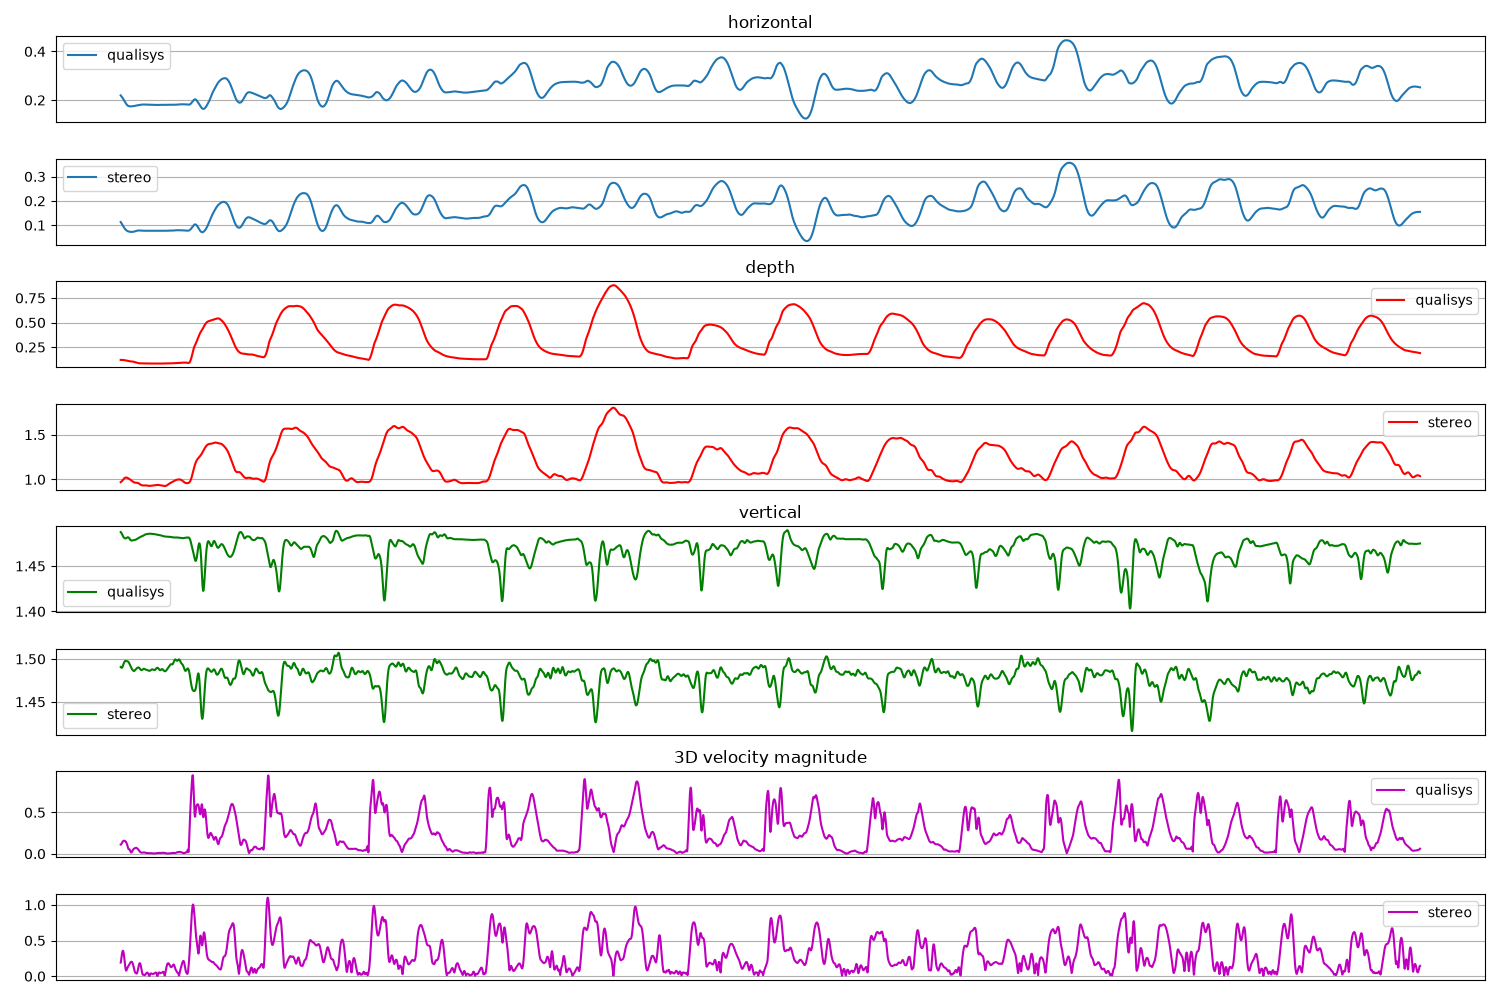

In [ ]:
import os
import json
import matplotlib.pyplot as plt
%matplotlib ipympl
from Util.util import load_keypoints_and_labels, get_velocity_and_acceleration, filter_keypoints_stereo, get_frame_times, resample_keypoints_to_rate
recording_name = 'pq1'

filename_qualisys_keypoints = os.path.join('data',recording_name,recording_name+'_qualisys.npz')
qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(filename=filename_qualisys_keypoints)

filename_stereo_keypoints = os.path.join('data',recording_name,recording_name+'_stereo.npz')
stereo_keypoints, stereo_labels = load_keypoints_and_labels(filename=filename_stereo_keypoints)

filename_timestamps = os.path.join('data', recording_name, recording_name + '_timestamps_color.bin')
filename_metadata = os.path.join('data', recording_name, recording_name+'_metadata.json')
with open(filename_metadata) as f:
    metadata = json.load(f)


KPT_NAME = 'mid_shoulder'


frames, times, fps = get_frame_times(filename_timestamps, n_frames=len(stereo_keypoints))
stereo_keypoints = filter_keypoints_stereo(stereo_keypoints[frames], sampling_rate=fps, cutoffs=(3, 3, 5))
stereo_keypoints, _ = resample_keypoints_to_rate(stereo_keypoints, times, 100)

stereo_cut= 390
qualisys_cut = 6050

stereo_velocity_3d, stereo_acceleration_3d = get_velocity_and_acceleration(keypoint=stereo_keypoints[stereo_cut:, stereo_labels.index(KPT_NAME),:],fps=100)
qualisys_velocity_3d, qualisys_acceleration_3d = get_velocity_and_acceleration(keypoint=qualisys_keypoints[:qualisys_cut,qualisys_labels.index(KPT_NAME),:], fps=100)


plt.close('all')
fig, axs = plt.subplots(8,1, figsize=(15,10))

axs[0].set_title('horizontal')
axs[0].plot(qualisys_keypoints[:qualisys_cut, qualisys_labels.index(KPT_NAME),1], label='qualisys')
axs[1].plot(stereo_keypoints[stereo_cut:,stereo_labels.index(KPT_NAME),0], label='stereo')

axs[2].set_title('depth')
axs[2].plot(qualisys_keypoints[:qualisys_cut, qualisys_labels.index(KPT_NAME),0], label='qualisys',color='r')
axs[3].plot(stereo_keypoints[stereo_cut:,stereo_labels.index(KPT_NAME),1],label='stereo', color = 'r')

axs[4].set_title('vertical')
axs[4].plot(qualisys_keypoints[:qualisys_cut, qualisys_labels.index(KPT_NAME),2], label='qualisys',color='g')
axs[5].plot(-stereo_keypoints[stereo_cut:,stereo_labels.index(KPT_NAME),2],label='stereo', color='g')

axs[6].set_title('3D velocity magnitude')
axs[6].plot(qualisys_velocity_3d, label='qualisys', color='m')
axs[7].plot(stereo_velocity_3d, label='stereo', color='m')

for ax in axs:
    ax.grid()
    ax.legend()
    ax.set_xticks([])
plt.tight_layout()

In [4]:
fps

np.float64(59.75500278150444)

# Pipeline check
(depth align, depth filter,) 2D keypoints, 2D filter, 3D keypoints, 3D filter, 3D spatial calibrated

In [2]:
import os
import json
import cv2
import time
import subprocess
import numpy as np
import pyrealsense2 as rs
from Util.util import load_keypoints_and_labels
import matplotlib.pyplot as plt
%matplotlib ipympl

recording_name = "pull1"
filename_metadata = os.path.join("data", recording_name, recording_name + "_metadata.json")
filename_color_video = os.path.join('data', recording_name, recording_name+'_color.mp4')
filename_depth_video = os.path.join('data', recording_name, recording_name+'_depth.mkv')
filename_keypoints_2d = os.path.join("data", recording_name, recording_name + "_keypoints_2d.npy")
filename_keypoints_3d_global = os.path.join("data", recording_name, recording_name + "_keypoints_3d_global.npy")
filename_stereo_npz = os.path.join('data', recording_name, recording_name+'_stereo.npz')

for filename in [
    filename_metadata,
    filename_color_video,
    filename_depth_video,
    filename_keypoints_2d,
    filename_keypoints_3d_global,
    filename_stereo_npz
]:
    if not os.path.exists(filename):
        raise FileNotFoundError(f"File {filename} does not exist")


with open(filename_metadata) as f:
    metadata = json.load(f)

keypoints_2d = np.load(filename_keypoints_2d)
keypoints_3d_global = np.load(filename_keypoints_3d_global)
stereo_keypoints,stereo_labels = load_keypoints_and_labels(filename=filename_stereo_npz)

print(f"{'keypoints_2d:':<25} {keypoints_2d.shape}")
print(f"{'keypoints_3d_global:':<25} {keypoints_3d_global.shape}")
print(f"{'stereo_keypoints:':25} {stereo_keypoints.shape}")
print(f"{'labels:':25} {len(stereo_labels)}")

loaded data from: data\pull1\pull1_stereo.npz with keys: ['labels', 'keypoints']
keypoints_2d:             (5863, 19, 2)
keypoints_3d_global:      (5863, 19, 3)
stereo_keypoints:         (6466, 19, 3)
labels:                   19


### 2D

In [ ]:
# PLOT 2D COORDS
KPT_IDX = 6

plt.close("all")
fig, axs = plt.subplots(2, 1, figsize=(15, 5))
fig.suptitle("2D raw & filtered")

axs[0].set_title("horizontal")
axs[0].plot(keypoints_2d[:, KPT_IDX, 0], label="raw")

axs[1].set_title("vertical")
axs[1].plot(keypoints_2d[:, KPT_IDX, 1], label="raw")

for ax in axs:
    ax.grid()
    ax.legend(loc="lower right")
plt.tight_layout()

In [16]:
# OVERLAY 2D COORDS ON VIDEO
cap = cv2.VideoCapture(filename_color_video)
n_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)
frame_idx = 0
while frame_idx < n_frames-1:
    ret, frame = cap.read()
    w, h, _ = frame.shape
    if not ret or frame_idx >= len(keypoints_2d):
        break

    frame_raw = cv2.rotate(frame, cv2.ROTATE_90_COUNTERCLOCKWISE)

    for x, y in keypoints_2d[frame_idx]:

        if np.isfinite(x) and np.isfinite(y):
            cv2.circle(frame_raw, (int(x), int(y)), 3, (0, 0, 255), -1)

    cv2.putText(frame_raw, str(frame_idx), (40, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)
    cv2.putText(frame_raw, 'raw', (int(w/2), 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)

    cv2.imshow("Raw & Filtered 2D", frame_raw)

    # Press ESC to quit
    if cv2.waitKey(1) & 0xFF == 27:
        break

    frame_idx += 1
    # time.sleep(0.075)
    time.sleep(0.03)

cap.release()
cv2.destroyAllWindows()

### 3D

In [ ]:
# PLOT 3D COORDINATES INDIVIDUALLY
KPT_IDX = 6

plt.close('all')
fig, axs = plt.subplots(3,1, figsize=(15,5))
fig.suptitle('3D raw & filtered')

axs[0].set_title('horizontal')
axs[0].plot(keypoints_3d_global[:,KPT_IDX,0], label='raw')
axs[0].plot(stereo_keypoints[:,KPT_IDX,0], label='filtered')

axs[1].set_title('vertical')
axs[1].plot(keypoints_3d_global[:,KPT_IDX,1], label='raw')
axs[1].plot(stereo_keypoints[:,KPT_IDX,1], label='filtered')

axs[2].set_title('depth')
axs[2].plot(keypoints_3d_global[:,KPT_IDX,2], label='raw')
axs[2].plot(stereo_keypoints[:,KPT_IDX,2], label='filtered')


for ax in axs:
    ax.grid()
    ax.legend(loc="lower right")
plt.tight_layout()

In [10]:
# OVERLAY SAMPLED AREAS WITH DEPTH STREAM VISUALIZED
width = metadata["width"]
height = metadata["height"]
fps = metadata["fps"]
sampling_radius = 3

frame_size = width * height * 2  # 16 bits = 2 bytes per pixel
cmd = [
    "ffmpeg",
    "-v",
    "error",
    "-i",
    filename_depth_video,
    "-f",
    "rawvideo",
    "-pix_fmt",
    "gray16le",
    "-",
]
process = subprocess.Popen(cmd, stdout=subprocess.PIPE, bufsize=frame_size * 2)

frame_idx = 0

try:
    while True:
        raw = process.stdout.read(frame_size)
        if len(raw) != frame_size:
            break  # End of video

        depth_frame = np.frombuffer(raw, dtype="<u2").reshape(height, width)

        # Normalize for visualization only
        valid = depth_frame > 0
        # too_far = depth_frame > 5000
        display = np.zeros((height, width), dtype=np.uint8)

        if np.any(valid):
            values = depth_frame[valid]
            low, high = np.percentile(values, [2, 98])

            if high > low:
                display[valid] = np.clip(
                    (depth_frame[valid].astype(np.float32) - low) * 255.0 / (high - low), 0, 255
                ).astype(np.uint8)

        colored = cv2.applyColorMap(display, cv2.COLORMAP_TURBO)
        colored[~valid] = 0

        # check portrait-landscape conversion logic by drawing
        for x_portrait, y_portrait in keypoints_2d[frame_idx, :]:
            # 90 deg clockwise
            x_landscape = int(round(width - 1 - y_portrait))
            y_landscape = int(round(x_portrait))

            # 90 deg counterclockwise
            # x_landscape = int(round(y_portrait))
            # y_landscape = int(round(height-1-x_portrait))

            x_min, x_max = max(0, x_landscape - sampling_radius), min(
                width, x_landscape + sampling_radius + 1
            )
            y_min, y_max = max(0, y_landscape - sampling_radius), min(

                height, y_landscape + sampling_radius + 1
            )
            top_left_corner = (x_min, y_min)
            bottom_right_corner = (x_max - 1, y_max - 1)
            cv2.rectangle(
                img=colored,
                pt1=top_left_corner,
                pt2=bottom_right_corner,
                color=(255, 255, 255),
                thickness=-1,
            )

        cv2.imshow("Depth video", colored)
        key = cv2.waitKey(10) & 0xFF
        if key == ord("q"):
            break

        frame_idx += 1

finally:
    process.stdout.close()
    process.terminate()
    process.wait()
    cv2.destroyAllWindows()

## Draw keypoints

In [3]:
import numpy as np
import os
from Util.util import load_keypoints_and_labels
recording_name = 'tug1'
stereo_keypoints, stereo_labels = load_keypoints_and_labels(filename=os.path.join('data',recording_name,f'{recording_name}_stereo.npz'))
qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(filename=os.path.join('data', recording_name, recording_name+'_qualisys.npz'))

loaded data from: data\tug1\tug1_stereo.npz with keys: ['labels', 'keypoints']
loaded data from: data\tug1\tug1_qualisys.npz with keys: ['labels', 'keypoints']


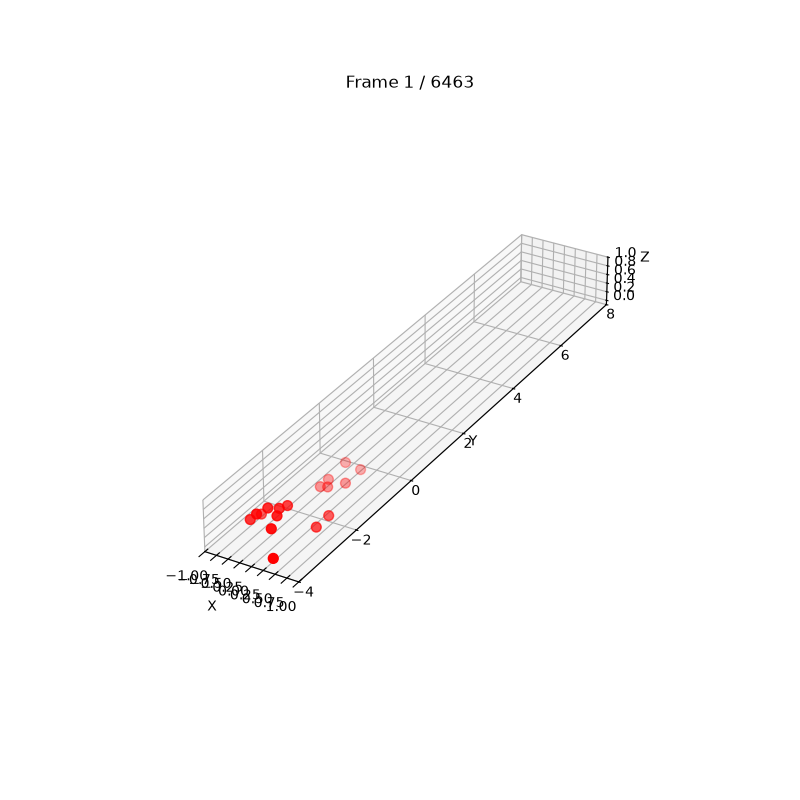

In [4]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib ipympl

frame = 0

plt.close('all')
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

keypoints = stereo_keypoints
# keypoints = qualisys_keypoints

def update():
    ax.clear()

    pts = keypoints[frame]

    # Plot all keypoints
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=50, c="red")

    ax.set_title(f"Frame {frame + 1} / {len(keypoints)}") 

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

    x_min, x_max = (-1,1)
    y_min, y_max = (-4,8)
    z_min, z_max = (-0.1,1)
    ax.set_xlim(x_min,x_max)
    ax.set_ylim(y_min,y_max)
    ax.set_zlim(z_min,z_max)
    ax.set_box_aspect([x_max-x_min, y_max-y_min, z_max-z_min])

    fig.canvas.draw_idle()


def on_key(event):
    global frame

    if event.key == "right":
        frame = min(frame + 1, len(keypoints) - 1)
        update()

    elif event.key == "left":
        frame = max(frame - 1, 0)
        update()
    elif event.key == "up":
        frame = min(frame + 30, len(keypoints) - 1)
        update()
    elif event.key == "down":
        frame = max(frame - 30, 0)
        update()

fig.canvas.mpl_connect("key_press_event", on_key)

update()
plt.show()

# Small tests

## Kalman filter

### Get baseline noise

In [68]:
import os
import json 
import numpy as np
import matplotlib.pyplot as plt
from Util.util import *
%matplotlib ipympl

In [40]:
recording_name = 'noise_close'
keypoints_3d_noise = np.load(os.path.join('data', recording_name, recording_name+'_keypoints_3d_global.npy'))
print(f'keypoints: {keypoints_3d_noise.shape}')

KPT_IDX = 26

kpt = keypoints_3d_noise[400:,KPT_IDX,:3400]
static_std = np.nanstd(kpt, axis=0)
static_std

keypoints: (1491, 27, 3)


array([0.00270537, 0.00613548, 0.00128089])

### Filter

In [73]:
import numpy as np
from filterpy.kalman import KalmanFilter


def make_kalman_filter(dt, noise_std_xyz, acceleration_std=2.0):
    """
    Constant-velocity Kalman filter for one 3D point.

    State: [x, y, z, vx, vy, vz]. Measurement: [x, y, z].

    Parameters
    ----------
    dt : float Time between frames in seconds.
    noise_std_xyz : float or array-like of shape (3,) Measurement noise std in meters (scalar or per-axis).
    acceleration_std : float Std of the unmodelled acceleration in m/s^2 (drives process noise Q).
    """
    kf = KalmanFilter(dim_x=6, dim_z=3)

    # State transition: position += velocity * dt
    kf.F = np.eye(6)
    kf.F[:3, 3:] = np.eye(3) * dt

    # Measurement matrix: observe X, Y, Z only
    kf.H = np.zeros((3, 6))
    kf.H[:3, :3] = np.eye(3)

    # Measurement covariance (accepts scalar or per-axis std)
    std = np.broadcast_to(np.asarray(noise_std_xyz, dtype=float), (3,))
    kf.R = np.diag(std**2)

    # Process noise: discrete white-noise acceleration model
    G = np.vstack(
        (
            np.eye(3) * (0.5 * dt**2),
            np.eye(3) * dt,
        )
    )
    kf.Q = G @ G.T * acceleration_std**2

    # Initial P is set per track, once the first valid measurement arrives.
    return kf


def kalman_filter_keypoints(
    data,
    dt,
    measurement_std=0.02,
    acceleration_std=2.0,
    velocity_std=1.0,
):
    """
    Parameters
    ----------
    data : ndarray, shape (n_frames, n_keypoints, 3) 3D keypoints in meters. NaN indicates missing measurements.
    dt : float Time between frames in seconds.
    measurement_std : float or array-like of shape (3,) Measurement noise std in meters.
    acceleration_std : float
    Process noise: std of unmodelled acceleration in m/s^2.
    velocity_std : floatPrior std of the initial velocity in m/s.

    Returns
    -------
    filtered : ndarray, same shape as data Frames before a keypoint's first valid measurement stay NaN.
    """
    data = np.asarray(data, dtype=float)

    if data.ndim != 3 or data.shape[2] != 3:
        raise ValueError("Expected shape (n_frames, n_keypoints, 3)")

    n_frames, n_keypoints, _ = data.shape
    filtered = np.full_like(data, np.nan)

    pos_var = np.broadcast_to(np.asarray(measurement_std, dtype=float), (3,)) ** 2

    for j in range(n_keypoints):
        kf = make_kalman_filter(dt, measurement_std, acceleration_std)
        initialized = False

        for t in range(n_frames):
            z = data[t, j]
            valid = np.all(np.isfinite(z))

            if not initialized:
                if not valid:
                    continue

                kf.x = np.zeros(6)
                kf.x[:3] = z
                # 6x6: position variance = measurement variance, velocity prior
                kf.P = np.diag(np.concatenate([pos_var, np.full(3, velocity_std**2)]))
                initialized = True
                filtered[t, j] = z
                continue

            kf.predict()

            if valid:
                kf.update(z)

            filtered[t, j] = kf.x[:3]

    return filtered

In [79]:
keypoints_raw[:,18:20,:].shape

(3000, 2, 3)

In [80]:
recording_name = "pq1"
filename_metadata = os.path.join("data", recording_name, recording_name + "_metadata.json")
filename_keypoints_3d_global = os.path.join("data", recording_name, recording_name + "_keypoints_3d_global.npy")
filename_qualisys = os.path.join('data', recording_name, recording_name+'_qualisys.npz')

keypoints_raw = np.load(filename_keypoints_3d_global)
with open(filename_metadata) as f:
    metadata = json.load(f)

keypoints_raw = keypoints_raw[400:3400,:,:]
keypoints_kalman = kalman_filter_keypoints(data=keypoints_raw[:,18:20,:],dt=1/metadata['fps'], measurement_std=static_std)
keypoints_qualisys, qualisys_labels = load_keypoints_and_labels(filename=filename_qualisys)

loaded data from: data\pq1\pq1_qualisys.npz with keys: ['labels', 'keypoints']


IndexError: index 26 is out of bounds for axis 1 with size 2

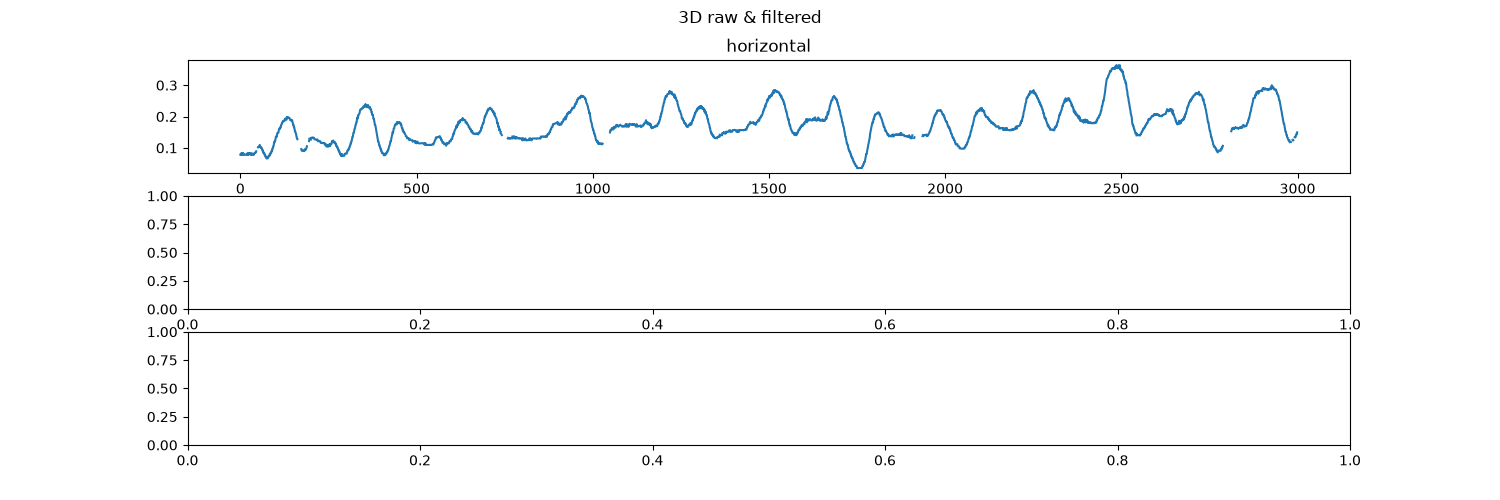

In [81]:
# PLOT 3D COORDINATES INDIVIDUALLY
KPT_NAME = 'mid_shoulder'

plt.close('all')
fig, axs = plt.subplots(3,1, figsize=(15,5))
fig.suptitle('3D raw & filtered')

axs[0].set_title('horizontal')
axs[0].plot(keypoints_raw[:,labels.index(KPT_NAME),0], label='raw')
axs[0].plot(keypoints_kalman[:,labels.index(KPT_NAME),0], label='filtered')

axs[1].set_title('vertical')
axs[1].plot(keypoints_raw[:,labels.index(KPT_NAME),1], label='raw')
axs[1].plot(keypoints_kalman[:,labels.index(KPT_NAME),1], label='filtered')

axs[2].set_title('depth')
axs[2].plot(keypoints_raw[:,labels.index(KPT_NAME),2], label='raw')
axs[2].plot(keypoints_kalman[:,labels.index(KPT_NAME),2], label='filtered')


for ax in axs:
    ax.grid()
    ax.legend(loc="lower right")
plt.tight_layout()

C:\Users\unger\AppData\Local\Temp\ipykernel_9540\1449411974.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[4].legend()


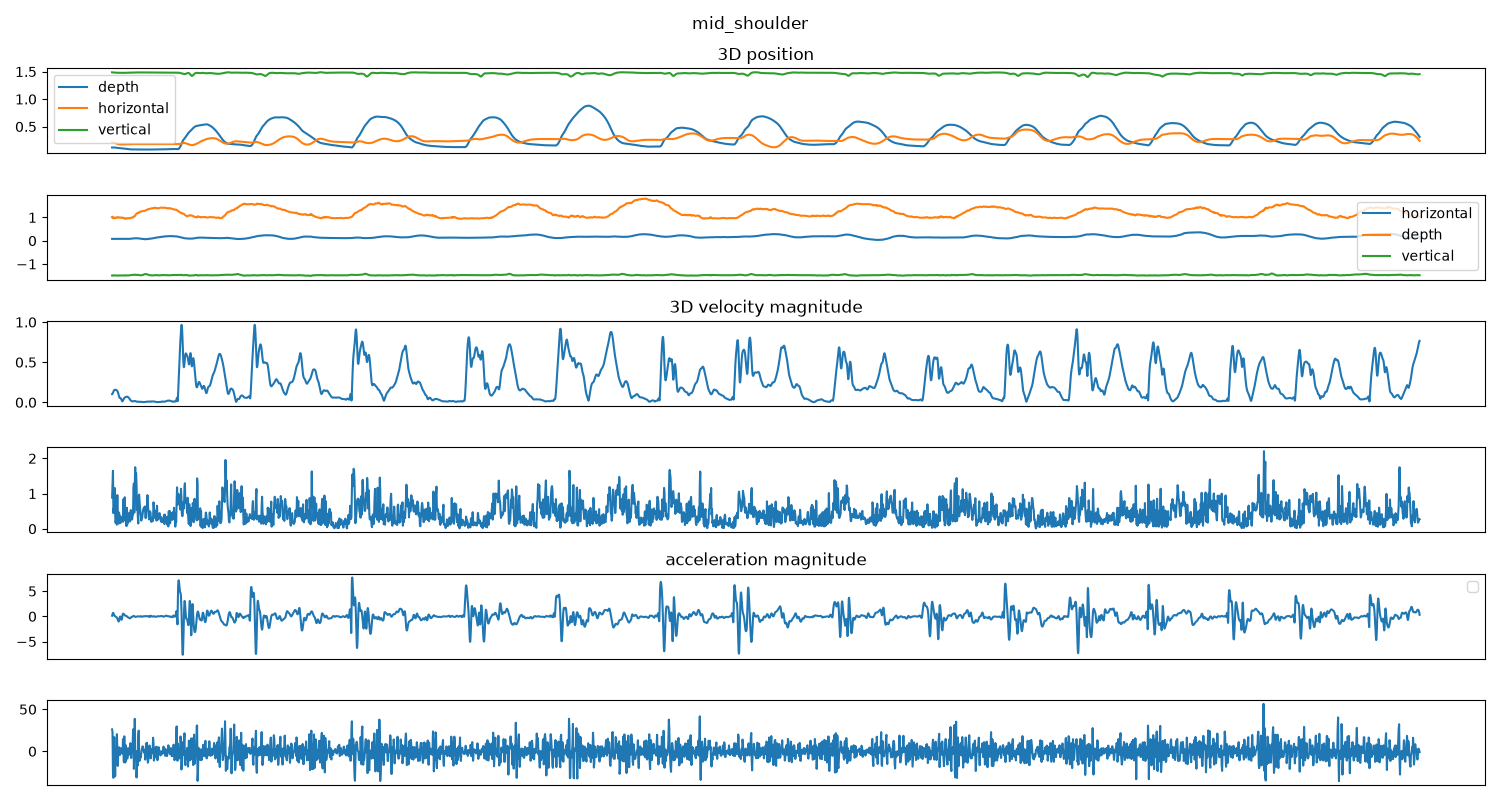

In [73]:
qualisys_kpt = keypoints_qualisys[:6300, qualisys_labels.index(KPT_NAME), :]

stereo_velocity, stereo_acceleration = get_velocity_and_acceleration(
    keypoint=keypoints_kalman[:,labels.index(KPT_NAME),:], fps=metadata["fps"]
)
qualisys_velocity, qualisys_acceleration = get_velocity_and_acceleration(
    keypoint=qualisys_kpt, fps=100
)


plt.close("all")
fig, axs = plt.subplots(6, 1, figsize=(15, 8))
fig.suptitle(KPT_NAME)

axs[0].set_title("3D position")
axs[0].plot(qualisys_kpt, label=["depth", "horizontal", "vertical"])
axs[0].legend()

axs[1].plot(keypoints_kalman[:,labels.index(KPT_NAME),:], label=["horizontal", "depth", "vertical"])
axs[1].legend()

axs[2].set_title("3D velocity magnitude")
axs[2].plot(qualisys_velocity)

axs[3].plot(stereo_velocity)

axs[4].set_title("acceleration magnitude")
axs[4].plot(qualisys_acceleration)
axs[4].legend()

axs[5].plot(stereo_acceleration, label="'raw'")



for ax in axs[:]:
    ax.set_xticks([])
    # ax.vlines(170, -10,10)
    # ax.vlines(380, -10,10)
    # ax.vlines(690, -10,10)
    # ax.vlines(895, -10,10)
    # ax.vlines(1190, -10,10)
    # ax.vlines(1495, -10,10)
    # ax.vlines(1750, -10,10)
    # ax.vlines(2050, -10,10)
    # ax.vlines(2310, -10,10)
    # ax.vlines(2600, -10,10)
    # ax.vlines(2900, -10,10)
    # ax.vlines(3175, -10,10)
plt.tight_layout()

### bs

In [74]:
import numpy as np
from filterpy.kalman import KalmanFilter

# 99th percentile of a chi-square distribution with 3 degrees of freedom
CHI2_99_DOF3 = 11.34


def make_kalman_filter(dt, noise_std_xyz, acceleration_std=2.0):
    """
    Constant-velocity Kalman filter for one 3D point.

    State: [x, y, z, vx, vy, vz]. Measurement: [x, y, z].

    Parameters
    ----------
    dt : float
        Time between frames in seconds.
    noise_std_xyz : float or array-like of shape (3,)
        Measurement noise std in meters (scalar or per-axis).
    acceleration_std : float
        Std of the unmodelled acceleration in m/s^2 (drives process noise Q).
    """
    kf = KalmanFilter(dim_x=6, dim_z=3)

    # State transition: position += velocity * dt
    kf.F = np.eye(6)
    kf.F[:3, 3:] = np.eye(3) * dt

    # Measurement matrix: observe X, Y, Z only
    kf.H = np.zeros((3, 6))
    kf.H[:3, :3] = np.eye(3)

    # Measurement covariance (accepts scalar or per-axis std)
    std = np.broadcast_to(np.asarray(noise_std_xyz, dtype=float), (3,))
    kf.R = np.diag(std**2)

    # Process noise: discrete white-noise acceleration model
    G = np.vstack(
        (
            np.eye(3) * (0.5 * dt**2),
            np.eye(3) * dt,
        )
    )
    kf.Q = G @ G.T * acceleration_std**2

    # Initial P is set per track, once the first valid measurement arrives.
    return kf


def _filter_track(track, dt, measurement_std, acceleration_std, velocity_std):
    """
    Run the filter over one keypoint track, shape (n_frames, 3).

    Returns
    -------
    xs : (n_frames, 6) posterior states (NaN before the first valid frame)
    Ps : (n_frames, 6, 6) posterior covariances
    nis : (n_frames,) normalized innovation squared at frames with a
          measurement (NaN elsewhere). Should average ~3 if tuned well.
    loglik : float, total measurement log-likelihood of the track
    first : index of the first valid frame, or None if there is none
    """
    n = len(track)
    kf = make_kalman_filter(dt, measurement_std, acceleration_std)
    pos_var = np.broadcast_to(np.asarray(measurement_std, dtype=float), (3,)) ** 2

    xs = np.full((n, 6), np.nan)
    Ps = np.full((n, 6, 6), np.nan)
    nis = np.full(n, np.nan)
    loglik = 0.0
    first = None

    for t in range(n):
        z = track[t]
        valid = np.all(np.isfinite(z))

        if first is None:
            if not valid:
                continue
            kf.x = np.zeros(6)
            kf.x[:3] = z
            kf.P = np.diag(np.concatenate([pos_var, np.full(3, velocity_std**2)]))
            first = t
            xs[t], Ps[t] = kf.x, kf.P
            continue

        kf.predict()

        if valid:
            y = z - kf.H @ kf.x
            S = kf.H @ kf.P @ kf.H.T + kf.R
            nis[t] = y @ np.linalg.solve(S, y)
            loglik -= 0.5 * (nis[t] + np.linalg.slogdet(S)[1] + 3 * np.log(2 * np.pi))
            kf.update(z)

        xs[t], Ps[t] = kf.x, kf.P

    return xs, Ps, nis, loglik, first


def _rts_smooth(xs, Ps, F, Q, first):
    """Rauch-Tung-Striebel backward pass. Removes the filter's lag (offline only)."""
    out = xs.copy()
    for t in range(len(xs) - 2, first - 1, -1):
        P_pred = F @ Ps[t] @ F.T + Q
        C = Ps[t] @ F.T @ np.linalg.inv(P_pred)
        out[t] = xs[t] + C @ (out[t + 1] - F @ xs[t])
    return out


def kalman_filter_keypoints(
    data,
    dt,
    measurement_std=0.02,
    acceleration_std=2.0,
    velocity_std=1.0,
    smooth=False,
):
    """
    Parameters
    ----------
    data : ndarray, shape (n_frames, n_keypoints, 3)
        3D keypoints in meters. NaN indicates missing measurements.
    dt : float
        Time between frames in seconds.
    measurement_std : float or array-like of shape (3,)
        Measurement noise std in meters. Best estimated from a stationary
        stretch of data.
    acceleration_std : float
        Process noise: std of unmodelled acceleration in m/s^2. This is the
        main knob for sudden motion: too low and the filter lags behind it.
    velocity_std : float
        Prior std of the initial velocity in m/s.
    smooth : bool
        If True, run an RTS smoother after filtering (uses future frames, so
        no lag, but only valid for offline processing).

    Returns
    -------
    filtered : ndarray, same shape as data
        Frames before a keypoint's first valid measurement stay NaN.
    """
    data = np.asarray(data, dtype=float)

    if data.ndim != 3 or data.shape[2] != 3:
        raise ValueError("Expected shape (n_frames, n_keypoints, 3)")

    n_frames, n_keypoints, _ = data.shape
    filtered = np.full_like(data, np.nan)
    kf = make_kalman_filter(dt, measurement_std, acceleration_std)

    for j in range(n_keypoints):
        xs, Ps, _, _, first = _filter_track(
            data[:, j], dt, measurement_std, acceleration_std, velocity_std
        )
        if first is None:
            continue
        if smooth:
            xs = _rts_smooth(xs, Ps, kf.F, kf.Q, first)
        filtered[first:, j] = xs[first:, :3]

    return filtered


def tune_acceleration_std(
    data,
    dt,
    measurement_std=0.02,
    candidates=(1, 2, 5, 10, 20, 40, 80),
    velocity_std=1.0,
):
    """
    Score candidate acceleration_std values on your own data.

    For each candidate, prints the total log-likelihood (higher is better),
    the mean NIS (should be ~3 for 3D measurements) and the fraction of
    frames with NIS above the 99% chi-square threshold (should be ~0.01).
    A mean NIS well above 3 means the filter is overconfident in its
    constant-velocity prediction: that is the lag you see at sudden pulls.

    Returns (best_acceleration_std, rows).
    """
    data = np.asarray(data, dtype=float)
    rows = []
    for a in candidates:
        ll, all_nis = 0.0, []
        for j in range(data.shape[1]):
            _, _, nis, ll_j, _ = _filter_track(
                data[:, j], dt, measurement_std, a, velocity_std
            )
            ll += ll_j
            all_nis.append(nis[np.isfinite(nis)])
        all_nis = np.concatenate(all_nis)
        rows.append((a, ll, all_nis.mean(), (all_nis > CHI2_99_DOF3).mean()))

    print(f"{'acc_std':>8} {'loglik':>12} {'mean NIS (~3)':>14} {'frac > 11.34 (~0.01)':>22}")
    for a, ll, m, f in rows:
        print(f"{a:8.1f} {ll:12.1f} {m:14.2f} {f:22.3f}")

    best = max(rows, key=lambda r: r[1])[0]
    return best, rows

In [75]:
best, rows = tune_acceleration_std(keypoints_raw,1/60,static_std)

 acc_std       loglik  mean NIS (~3)   frac > 11.34 (~0.01)
     1.0  -34756580.5         890.13                  0.334
     2.0  -26046620.2         673.60                  0.238
     5.0  -18173410.1         477.27                  0.152
    10.0  -13774078.5         366.96                  0.109
    20.0   -9990329.8         271.50                  0.077
    40.0   -6728188.2         188.47                  0.054
    80.0   -4160825.4         122.15                  0.037


C:\Users\unger\AppData\Local\Temp\ipykernel_9540\2786640730.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2].legend()


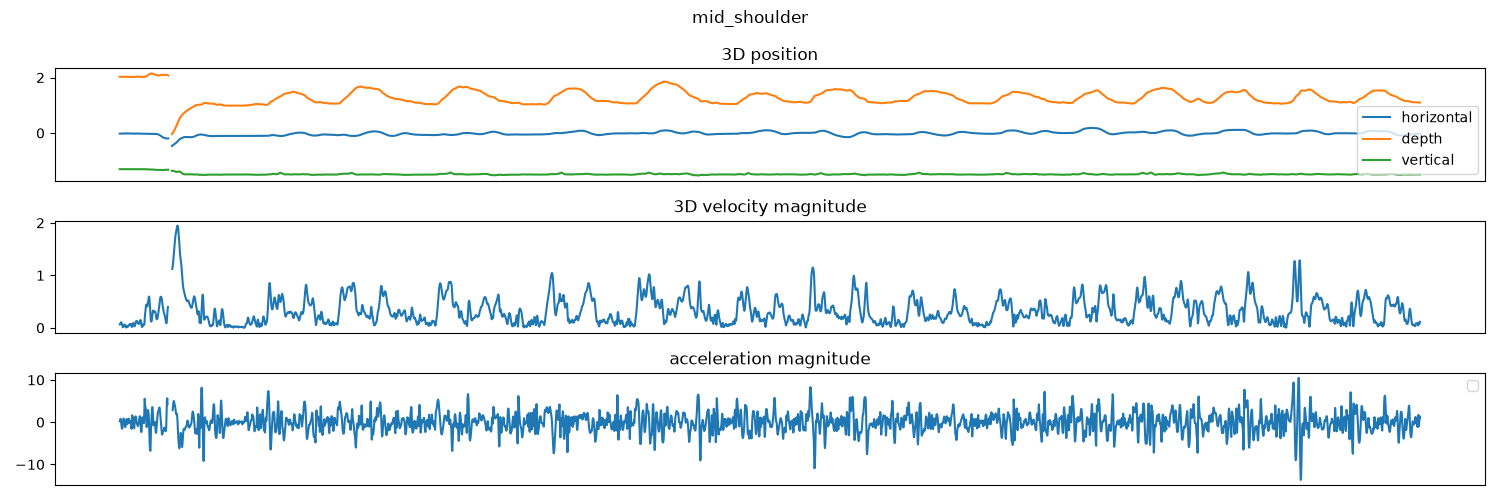

In [84]:
data = np.load("filtered_keypoints_6.npy")
KPT_IDX = 0
stereo_velocity, stereo_acceleration = get_velocity_and_acceleration(
    keypoint=data[:,KPT_IDX,:], fps=metadata["fps"]
)



plt.close("all")
fig, axs = plt.subplots(3, 1, figsize=(15, 5))
fig.suptitle(KPT_NAME)

axs[0].set_title("3D position")
axs[0].plot(data[:,KPT_IDX,:], label=["horizontal", "depth", "vertical"])
axs[0].legend()

axs[1].set_title("3D velocity magnitude")
axs[1].plot(stereo_velocity)


axs[2].set_title("acceleration magnitude")
axs[2].plot(stereo_acceleration)
axs[2].legend()



for ax in axs[:]:
    ax.set_xticks([])
    # ax.vlines(170, -10,10)
    # ax.vlines(380, -10,10)
    # ax.vlines(690, -10,10)
    # ax.vlines(895, -10,10)
    # ax.vlines(1190, -10,10)
    # ax.vlines(1495, -10,10)
    # ax.vlines(1750, -10,10)
    # ax.vlines(2050, -10,10)
    # ax.vlines(2310, -10,10)
    # ax.vlines(2600, -10,10)
    # ax.vlines(2900, -10,10)
    # ax.vlines(3175, -10,10)
plt.tight_layout()

## savgol filter

In [ ]:
import numpy as np
from scipy.signal import savgol_filter


def _smooth_runs(kp: np.ndarray, window_frames: int, polyorder: int) -> np.ndarray:
    """Savgol-filter each contiguous valid run. NaN gaps and runs shorter
    than the window stay NaN."""
    out = np.full(kp.shape, np.nan)
    for kpt, dim in np.ndindex(kp.shape[1], kp.shape[2]):
        coord = kp[:, kpt, dim]
        for start, end in get_segment_borders(~np.isnan(coord)):
            if end - start >= window_frames:
                out[start:end, kpt, dim] = savgol_filter(
                    coord[start:end], window_frames, polyorder
                )
    return out


def sweep(kp, fps, polyorder, windows_s, gap_size):
    """
    kp: (n_frames, n_kpt, n_dims), raw, may contain NaNs
    Returns rows of (window_s, window_frames, residual_rms, accel_rms, frac_valid).
    """
    kp = interpolate_gaps(kp, fps, gap_size)

    smoothed = {}
    for w in windows_s:
        n = int(round(w * fps))
        n += n % 2 == 0                        # force odd
        if n <= polyorder or n > kp.shape[0]:
            continue
        smoothed[w] = (n, _smooth_runs(kp, n, polyorder))
    if not smoothed:
        raise ValueError("no valid window lengths for this polyorder/signal length")

    # Compare all windows on the same samples: longer windows drop more short
    # runs, which would otherwise change what each metric is averaged over.
    common = np.all([np.isfinite(sm) for _, sm in smoothed.values()], axis=0)

    rows = []
    for w, (n, sm) in smoothed.items():
        sm_c = np.where(common, sm, np.nan)
        resid_rms = np.sqrt(np.nanmean((kp - sm_c) ** 2))
        acc = np.diff(sm_c, n=2, axis=0) * fps**2      # NaNs propagate locally
        acc_rms = np.sqrt(np.nanmean(acc**2))
        rows.append((w, n, resid_rms, acc_rms, np.isfinite(sm).mean()))
    return np.array(rows)


res = sweep(keypoints_3d_global[850:,:,:], metadata['fps'], polyorder=4, windows_s=np.arange(0.1, 0.81, 0.05), gap_size=0.1)

In [ ]:
res

In [ ]:
fig, ax = plt.subplots(3, 1, sharex=True, figsize=(6, 7))
ax[0].plot(res[:, 0], res[:, 2], "o-"); ax[0].set_ylabel("residual RMS")
ax[1].plot(res[:, 0], res[:, 3], "o-"); ax[1].set_ylabel("accel RMS")
ax[2].plot(res[:, 0], res[:, 4], "o-"); ax[2].set_ylabel("valid fraction")
ax[2].set_xlabel("window (s)")
plt.show()

In [ ]:
def accel_by_channel(kp, fps, window_s, polyorder, gap_size):
    kp = interpolate_gaps(kp, fps, gap_size)
    n = int(round(window_s * fps)); n += n % 2 == 0
    sm = _smooth_runs(kp, n, polyorder)
    acc = np.diff(sm, n=2, axis=0) * fps**2
    rms = np.sqrt(np.nanmean(acc**2, axis=0))             # (n_kpt, n_dims)
    robust = 1.4826 * np.nanmedian(np.abs(acc), axis=0)   # MAD-style, ignores spikes
    return rms, robust

In [ ]:
kp = interpolate_gaps(keypoints_3d_global[850:,:,:], metadata['fps'], 0.25)
step = np.diff(kp, axis=0)                       # frame-to-frame change
print(np.nanstd(step, axis=0).mean(axis=0))      # per dim (x, y, z)
print(np.nanpercentile(np.abs(step), 99.9, axis=0).max(axis=0))  # worst jumps per dim

rms, robust = accel_by_channel(keypoints_3d_global[850:,:,:], metadata['fps'], 0.3, 4, 0.25)
print(rms / robust)   

In [ ]:
import numpy as np
import pandas as pd

def reject_outliers(kp, window_frames=9, max_dev=0.10):
    """
    kp: (n_frames, n_kpt, n_dims). Samples further than max_dev (same units as
    kp, e.g. meters) from the rolling median are set to NaN, for all dims of
    that keypoint at once.
    """
    n, k, d = kp.shape
    med = (
        pd.DataFrame(kp.reshape(n, -1))
        .rolling(window_frames, center=True, min_periods=3)
        .median()
        .to_numpy()
        .reshape(n, k, d)
    )
    bad = np.linalg.norm(kp - med, axis=2) > max_dev       # (n_frames, n_kpt)
    out = kp.astype(float, copy=True)
    out[bad] = np.nan
    return out, bad

kp_clean, bad = reject_outliers(keypoints_3d_global[850:,:,:])
print(bad.mean(axis=0).round(3))   # fraction rejected per keypoint

In [ ]:
res = sweep(kp_clean, metadata['fps'], polyorder=4, windows_s=np.arange(0.1, 0.81, 0.05), gap_size=0.1)

In [ ]:
res

In [ ]:
def butter_sweep(kp, fps, cutoffs, order=4):
    # kp: (n_frames, n_kpt, n_dims), gap-filled, NaN-free stretch
    rows = []
    for fc in cutoffs:
        sos = butter(order, fc, fs=fps, output="sos")
        sm = sosfiltfilt(sos, kp, axis=0)
        resid = np.sqrt(np.mean((kp - sm) ** 2))
        acc = np.diff(sm, n=2, axis=0) * fps**2
        rows.append((fc, resid, 1.4826 * np.median(np.abs(acc))))  # robust, spike-proof
    return np.array(rows)

res_b = butter_sweep(kp_clean, fps, cutoffs=np.arange(2, 16, 1.0))

In [ ]:
res_b

## Detector selection

In [ ]:
# PLOT 2D COORDS
KPT_IDX = 18

kpts_nano = np.load(os.path.join('data', 'w1', 'w1_keypoints_2d_nano.npy'))
kpts_x = np.load(os.path.join('data', 'w1', 'w1_keypoints_2d_x.npy'))

kpts_nano = kpts_nano[400:,:,:]
kpts_x = kpts_x[400:,:,:]

vel_nano = np.linalg.norm(np.gradient(kpts_nano[:, KPT_IDX, :], axis=0), axis=1)
acc_nano = np.gradient(vel_nano, axis=0)

vel_x = np.linalg.norm(np.gradient(kpts_x[:, KPT_IDX, :], axis=0), axis=1)
acc_x = np.gradient(vel_x, axis=0)


plt.close("all")
fig, axs = plt.subplots(4, 1, figsize=(15, 8))
fig.suptitle("2D raw & filtered")

axs[0].set_title("horizontal")
axs[0].plot(kpts_nano[:, KPT_IDX, 0], label="nano")
axs[0].plot(kpts_x[:, KPT_IDX, 0], label="x")

axs[1].set_title("vertical")
axs[1].plot(kpts_nano[:, KPT_IDX, 1], label="nano")
axs[1].plot(kpts_x[:, KPT_IDX, 1], label="x")

axs[2].plot(vel_nano, label='nano')
axs[2].plot(vel_x, label='x')

axs[3].plot(acc_nano, label='nano')
axs[3].plot(acc_x, label='x')

for ax in axs:
    ax.grid()
    ax.legend(loc="lower right")
plt.tight_layout()

## Draw trajectories

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2

recording_name = 'q1'
# keypoints_2d = np.load(os.path.join('data',recording_name, recording_name+'_keypoints_2d.npy'))
print(keypoints_2d.shape)
KPT_IDX = 6
plt.close('all')
fig, axs = plt.subplots(3,1, figsize=(15,5))
axs[0].plot(keypoints_2d[:,KPT_IDX,:], label=['x','y'])
axs[0].legend()

In [ ]:
import cv2
import numpy as np
import time

video_path = os.path.join('data',recording_name, recording_name+'_color.mp4')

cap = cv2.VideoCapture(video_path)

frame_idx = 0

while True:
    ret, frame = cap.read()
    if not ret or frame_idx >= len(keypoints_2d):
        break

    frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)
    
    # Keypoints for this frame: (num_keypoints, 2)
    pts = keypoints_2d[frame_idx]

    # Draw circles
    for x, y in pts:
        if np.isfinite(x) and np.isfinite(y):
            cv2.circle(
                frame,
                (int(x), int(y)),
                3,              # radius
                (0, 0, 255),    # BGR = red
                -1              # filled
            )

    cv2.imshow("Pose", frame)

    # Press ESC to quit
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

    frame_idx += 1
    time.sleep(0.075)

cap.release()
cv2.destroyAllWindows()

In [ ]:
ord('q')

## Compressed depth

In [ ]:
import numpy as np
import blosc2

depth = np.asarray(depth_frame.get_data(), dtype=np.uint16)

compressed = blosc2.compress(
    depth,
    typesize=2,
    clevel=3,
    filter=blosc2.Filter.SHUFFLE,
    codec=blosc2.Codec.ZSTD
)

In [ ]:
raw = blosc2.decompress(compressed)

depth_restored = np.frombuffer(
    raw,
    dtype=np.uint16
).reshape(480, 848)

In [ ]:
assert np.array_equal(depth, depth_restored)

In [ ]:
import os
import json
import time
import struct

import cv2
import numpy as np
import pyrealsense2 as rs
import zstandard as zstd


recording_name = "asdf"

WIDTH = 848
HEIGHT = 480
FPS = 60
DURATION = 5

output_dir = os.path.join("data", recording_name)
os.makedirs(output_dir, exist_ok=True)

depth_filename = os.path.join(output_dir, "depth.zst")
color_filename = os.path.join(output_dir, "color.mp4")
timestamp_filename = os.path.join(output_dir, "timestamps.npz")
metadata_filename = os.path.join(output_dir, "metadata.json")

# REALSENSE SETUP
pipeline = rs.pipeline()
config = rs.config()

config.enable_stream(rs.stream.depth, WIDTH, HEIGHT, rs.format.z16, FPS)

config.enable_stream(rs.stream.color, WIDTH, HEIGHT, rs.format.bgr8, FPS)

queue = rs.frame_queue(capacity=30, keep_frames=True)


# CHECK CONFIGURATION
if not config.can_resolve(pipeline):
    raise RuntimeError(
        f"RealSense configuration cannot be resolved: " f"{WIDTH}x{HEIGHT} @ {FPS} FPS"
    )

print("Configuration OK")


# START CAMERA
profile = pipeline.start(config, queue)

device = profile.get_device()
depth_sensor = device.first_depth_sensor()
depth_scale = depth_sensor.get_depth_scale()

print("Depth scale:", depth_scale)


# COLOR VIDEO WRITER
# mp4v is widely available with OpenCV.
# It is LOSSY.
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

video_writer = cv2.VideoWriter(color_filename, fourcc, FPS, (WIDTH, HEIGHT))
if not video_writer.isOpened():
    pipeline.stop()
    raise RuntimeError("Could not open color video writer")


# DEPTH COMPRESSOR
# Level 1 is deliberately fast.
# Increase to 3 or 5 if CPU usage/storage size permits.
compressor = zstd.ZstdCompressor(level=1)


# OPEN OUTPUT FILEs
depth_file = open(depth_filename, "wb")
timestamps = []
frame_numbers = []


start_time = time.perf_counter()
frame_count = 0

try:

    while time.perf_counter() - start_time < DURATION:

        frames = queue.wait_for_frame()
        frames = frames.as_frameset()

        depth_frame = frames.get_depth_frame()
        color_frame = frames.get_color_frame()

        if not depth_frame or not color_frame:
            continue

        depth_image = np.asanyarray(depth_frame.get_data())
        depth_image = np.asarray(depth_image, dtype=np.uint16)

        # Compress the complete depth frame.
        compressed_depth = compressor.compress(depth_image.tobytes())

        depth_file.write(struct.pack("<I", len(compressed_depth)))
        depth_file.write(compressed_depth)

        # COLOR        
        color_image = np.asanyarray(color_frame.get_data())
        video_writer.write(color_image)
        
        # TIMESTAMPS        
        timestamps.append(frames.get_timestamp())
        frame_numbers.append(frames.get_frame_number())

        frame_count += 1

        # OPTIONAL DISPLAY
        depth_colormap = cv2.applyColorMap(
            cv2.convertScaleAbs(depth_image, alpha=0.03), cv2.COLORMAP_JET
        )
        display = np.hstack((color_image, depth_colormap))
        cv2.imshow("RealSense", display)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    depth_file.close()
    video_writer.release()

    cv2.destroyAllWindows()

    pipeline.stop()

# SAVE TIMESTAMPS

np.savez(
    timestamp_filename,
    timestamps=np.asarray(timestamps, dtype=np.float64),
    frame_numbers=np.asarray(frame_numbers, dtype=np.int64),
)

# SAVE METADATA

metadata = {
    "width": WIDTH,
    "height": HEIGHT,
    "fps": FPS,
    "frames": frame_count,
    "depth_format": "Z16",
    "depth_dtype": "uint16",
    "depth_compression": "zstd",
    "depth_compression_level": 1,
    "color_format": "BGR8",
    "color_container": "MP4",
    "color_codec": "mp4v",
    "depth_scale": depth_scale,
}

with open(metadata_filename, "w") as f:
    json.dump(metadata, f, indent=4)


print()
print("Recording finished")
print("Frames:", frame_count)
print("Expected:", FPS * DURATION)

print()
print("Files:")

for filename in [depth_filename, color_filename, timestamp_filename, metadata_filename]:
    size_mb = os.path.getsize(filename) / (1024**2)
    print(f"{filename}: {size_mb:.2f} MB")

## frame que test

In [ ]:
import pyrealsense2 as rs
import time

# Implement two "processing" functions, each of which
# occassionally lags and takes longer to process a frame.
def slow_processing(frame):
    n = frame.get_frame_number() 
    if n % 20 == 0:
        time.sleep(1/4)
    print(n)

def slower_processing(frame):
    n = frame.get_frame_number() 
    if n % 20 == 0:
        time.sleep(1)
    print(n)

def fast_processing(frame):
    n = frame.get_frame_number()
    print(n)

frame_numbers = {
    "fast": [],
    "slow": [],
    "slow_que": [],
    "slower": [],
    "slower_que": [],
}

try:

    pipeline = rs.pipeline()
    config = rs.config()
    config.enable_stream(rs.stream.depth, 640, 480, rs.format.z16, 30)
    config.enable_stream(rs.stream.color, 640, 480, rs.format.bgr8, 30)



    # FAST
    print('Fast callback')
    pipeline.start(config)
    start = time.time()
    while time.time() - start < 5:
        frames = pipeline.wait_for_frames()
        frame_numbers['fast'].append(frames.get_frame_number())
        fast_processing(frames)
    pipeline.stop()


    # SLOW
    # Start streaming to the slow processing function.
    # This stream will lag, causing the occasional frame drop.
    print("Slow callback")
    pipeline.start(config)
    start = time.time()
    while time.time() - start < 5:
        frames = pipeline.wait_for_frames()
        frame_numbers['slow'].append(frames.get_frame_number())
        slow_processing(frames)
    pipeline.stop()

    # SLOW + QUE
    # Start streaming to the the slow processing function by way of a frame queue.
    # This stream will occasionally hiccup, but the frame_queue will prevent frame loss.
    print("Slow callback + queue")
    queue = rs.frame_queue(50)
    pipeline.start(config, queue)
    start = time.time()
    while time.time() - start < 5:
        frames = queue.wait_for_frame()
        frame_numbers['slow_que'].append(frames.get_frame_number())
        slow_processing(frames)
    pipeline.stop()

    # SLOWER
    # Start streaming to the the slower processing function by way of a frame queue.
    # This stream will drop frames because the delays are long enough that the backed up
    # frames use the entire internal frame pool preventing the SDK from creating more frames.
    print("Slower callback + queue")
    queue = rs.frame_queue(50)
    pipeline.start(config, queue)
    start = time.time()
    while time.time() - start < 5:
        frames = queue.wait_for_frame()
        frame_numbers['slower'].append(frames.get_frame_number())
        slower_processing(frames)
    pipeline.stop()

    # SLOWER + QUE
    # Start streaming to the slower processing function by way of a keeping frame queue.
    # This stream will no longer drop frames because the frame queue tells the SDK
    # to remove the frames it holds from the internal frame queue, allowing the SDK to
    # allocate space for and create more frames .
    print("Slower callback + keeping queue")
    queue = rs.frame_queue(capacity=200, keep_frames=True)
    pipeline.start(config, queue)
    start = time.time()
    while time.time() - start < 5:
        frames = queue.wait_for_frame()
        frame_numbers['slower_que'].append(frames.get_frame_number())
        slower_processing(frames)
    pipeline.stop()

except Exception as e:
    print(e)
except:
    print("A different Error")
else:
    print("Done")

for key, value in frame_numbers.items():
    print(key, len(value))

In [ ]:
# type(frames)
frames.as_frameset()

In [ ]:
help(rs.composite_frame)

In [ ]:
for ind, frame in enumerate(frame_numbers['slower_que'],1):
    print(ind, frame)

In [ ]:
help(rs.frame_queue)

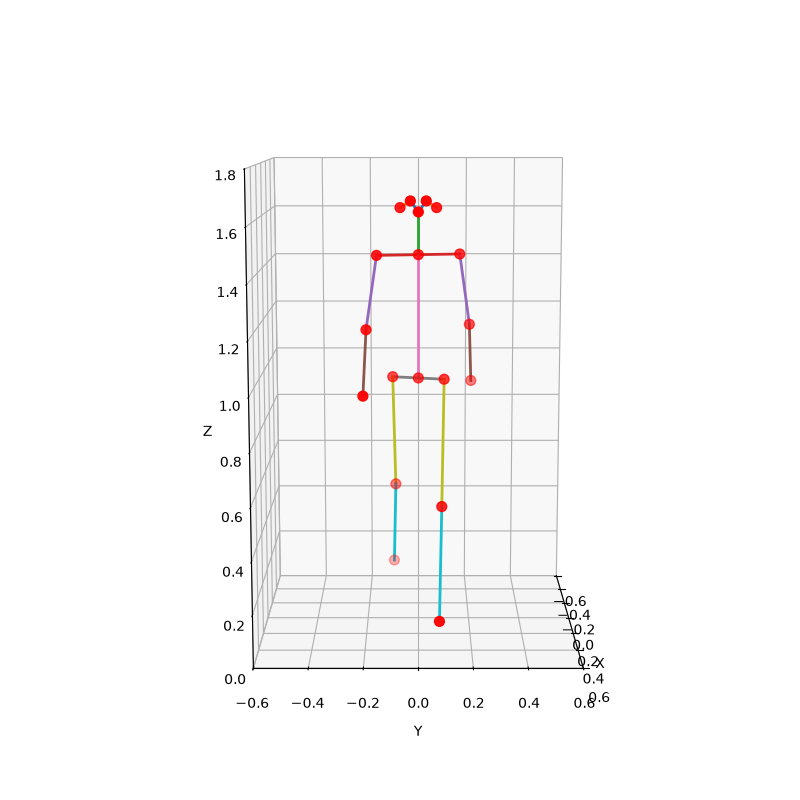

In [40]:
# plausible, hand-made 3D keypoints for a walking participant (mid stride), not measured.
# Axes in Qualisys order, meters: X depth (walking direction, toward the camera positive),
# Y horizontal (participant's left positive), Z vertical (up, floor at 0)
import numpy as np
import matplotlib.pyplot as plt
%matplotlib ipympl

# left leg forward (heel strike), right leg behind (push off), right arm swings forward
keypoints_by_label = {
    "nose": (0.10, 0.00, 1.62),
    "left_eye": (0.08, 0.03, 1.66),
    "right_eye": (0.08, -0.03, 1.66),
    "left_ear": (0.00, 0.07, 1.63),
    "right_ear": (0.00, -0.07, 1.63),
    "left_shoulder": (-0.03, 0.16, 1.45),
    "right_shoulder": (0.03, -0.16, 1.45),
    "left_elbow": (-0.08, 0.20, 1.17),
    "right_elbow": (0.08, -0.20, 1.17),
    "left_wrist": (-0.18, 0.21, 0.93),
    "right_wrist": (0.18, -0.21, 0.93),
    "left_hip": (0.03, 0.10, 0.97),
    "right_hip": (-0.03, -0.10, 0.97),
    "left_knee": (0.18, 0.09, 0.50),
    "right_knee": (-0.12, -0.09, 0.52),
    "left_ankle": (0.33, 0.08, 0.09),
    "right_ankle": (-0.35, -0.10, 0.14),
}
keypoints_by_label["mid_shoulder"] = tuple(
    np.mean([keypoints_by_label["left_shoulder"], keypoints_by_label["right_shoulder"]], axis=0)
)
keypoints_by_label["mid_hip"] = tuple(np.mean([keypoints_by_label["left_hip"], keypoints_by_label["right_hip"]], axis=0))

pts = np.array(list(keypoints_by_label.values()))

# bones as pairs of keypoints joined by a line, grouped so the left and right bone share a color;
# the midpoints form the neck and spine
skeleton = {
    "nose-eye": [("nose", "left_eye"), ("nose", "right_eye")],
    "eye-ear": [("left_eye", "left_ear"), ("right_eye", "right_ear")],
    "neck": [("nose", "mid_shoulder")],
    "shoulder": [("left_shoulder", "mid_shoulder"), ("right_shoulder", "mid_shoulder")],
    "upper arm": [("left_shoulder", "left_elbow"), ("right_shoulder", "right_elbow")],
    "forearm": [("left_elbow", "left_wrist"), ("right_elbow", "right_wrist")],
    "spine": [("mid_shoulder", "mid_hip")],
    "pelvis": [("left_hip", "mid_hip"), ("right_hip", "mid_hip")],
    "thigh": [("left_hip", "left_knee"), ("right_hip", "right_knee")],
    "shin": [("left_knee", "left_ankle"), ("right_knee", "right_ankle")],
}

plt.close('all')
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=50, c="red")
bone_colors = plt.get_cmap("tab10").colors
for bone_index, bone_pairs in enumerate(skeleton.values()):
    for start_label, end_label in bone_pairs:
        segment = np.array([keypoints_by_label[start_label], keypoints_by_label[end_label]])
        ax.plot(segment[:, 0], segment[:, 1], segment[:, 2], c=bone_colors[bone_index], linewidth=2)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
x_min, x_max = (-0.6, 0.6)
y_min, y_max = (-0.6, 0.6)
z_min, z_max = (0, 1.8)
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_zlim(z_min, z_max)
ax.set_box_aspect([x_max - x_min, y_max - y_min, z_max - z_min])
# start from the camera's view: in front of the participant (on +X, looking back along X), slightly above,
# with perspective like the RGB image; drag with the mouse to rotate
ax.view_init(elev=10, azim=0)
ax.set_proj_type("persp", focal_length=0.5)
plt.show()